# Feature causal thu gọn (build + quan sát)

Notebook **tự build** matrix 10 feature causal (không look-ahead) rồi quan sát phân phối / tương quan.

**Mục tiêu:** chuẩn bị input cho Isolation Forest / ECOD.

**Spec cột:** [`docs/feature_causal_spec.md`](../docs/feature_causal_spec.md)

**Các bước**
1. Load CSV tháng XK → tính `don_gia`
2. Log MoM / YoY
3. Robust z causal (`shift(1)` trước rolling — không nhìn tương lai)
4. Lưu `data/features/causal/*_causal.csv`
5. Vẽ timeline, heatmap, so missing


## 1. Cấu hình & thư viện

Đặt `ROOT` theo chỗ mở notebook (`scripts/` hoặc root repo).


In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path("..").resolve()
if not (ROOT / "data" / "csv" / "xuat_khau").exists():
    ROOT = Path(".").resolve()

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)
print("ROOT =", ROOT)

DATA_DIR = ROOT / "data" / "csv" / "xuat_khau"
OUT_DIR = ROOT / "data" / "features" / "causal"

FILES = [
    "gạo.csv",
    "sắt thép các loại.csv",
    "xăng dầu các loại.csv",
    "dầu thô.csv",
]

FEATURE_COLS = [
    "log_so_luong_mom",
    "log_so_luong_yoy",
    "log_tri_gia_mom",
    "log_tri_gia_yoy",
    "log_don_gia_mom",
    "log_don_gia_yoy",
    "so_luong_robust_z12",
    "tri_gia_robust_z12",
    "don_gia_robust_z12",
    "z_don_gia_minus_z_so_luong",
]
print("Features:", FEATURE_COLS)


ROOT = C:\Homework\Code File\ML docs\Anomaly Detection
Features: ['log_so_luong_mom', 'log_so_luong_yoy', 'log_tri_gia_mom', 'log_tri_gia_yoy', 'log_don_gia_mom', 'log_don_gia_yoy', 'so_luong_robust_z12', 'tri_gia_robust_z12', 'don_gia_robust_z12', 'z_don_gia_minus_z_so_luong']


## 2. Hàm build feature (no look-ahead)

- `robust_z_causal`: so `x_t` với median/MAD của **cửa sổ quá khứ** (`shift(1)` rồi mới rolling).
- MoM = `diff(1)` trên log; YoY = `diff(12)`.
- `z_don_gia_minus_z_so_luong`: lệch chuẩn hóa giá vs lượng.


In [2]:
def load_series(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)
    df["thang_nam"] = pd.to_datetime(df["thang_nam"])
    df = df.sort_values("thang_nam").set_index("thang_nam").asfreq("MS")
    qty = df["so_luong"]
    val = df["tri_gia"]
    df["don_gia"] = np.where(qty.notna() & (qty > 0) & val.notna(), val / qty, np.nan)
    return df


def robust_z_causal(s: pd.Series, window: int = 12) -> pd.Series:
    # Compare x_t to median/MAD of past window only (shift(1) before rolling)
    base = s.shift(1)
    min_p = max(3, window // 2)
    med = base.rolling(window, min_periods=min_p).median()
    mad = (base - med).abs().rolling(window, min_periods=min_p).median()
    scale = 1.4826 * mad.replace(0, np.nan)
    return (s - med) / scale


def build_compact(path: Path) -> pd.DataFrame:
    raw = load_series(path)
    out = pd.DataFrame(index=raw.index)
    out["loai"] = raw["loai"] if "loai" in raw.columns else "xuat_khau"
    if "ten_mat_hang" in raw.columns and raw["ten_mat_hang"].notna().any():
        out["ten_mat_hang"] = raw["ten_mat_hang"].dropna().iloc[0]
    else:
        out["ten_mat_hang"] = path.stem
    out["so_luong"] = raw["so_luong"]
    out["tri_gia"] = raw["tri_gia"]
    out["don_gia"] = raw["don_gia"]

    for col in ("so_luong", "tri_gia", "don_gia"):
        log_s = np.log(raw[col].astype(float).replace(0, np.nan))
        out[f"log_{col}_mom"] = log_s.diff(1)
        out[f"log_{col}_yoy"] = log_s.diff(12)
        out[f"{col}_robust_z12"] = robust_z_causal(raw[col].astype(float), 12)

    out["z_don_gia_minus_z_so_luong"] = out["don_gia_robust_z12"] - out["so_luong_robust_z12"]
    out["source_file"] = path.name
    return out


## 3. Build & lưu 4 chuỗi XK

Ghi CSV vào `data/features/causal/{stem}_causal.csv`.


In [3]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
built = {}
for name in FILES:
    path = DATA_DIR / name
    feat = build_compact(path)
    keep = ["loai", "ten_mat_hang", "so_luong", "tri_gia", "don_gia", *FEATURE_COLS, "source_file"]
    out = feat[keep]
    out_path = OUT_DIR / f"{path.stem}_causal.csv"
    out.to_csv(out_path, index=True)
    built[path.stem] = out
    n_feat = int(out[FEATURE_COLS].notna().any(axis=0).sum())
    print(f"Saved {out_path.relative_to(ROOT)}  rows={len(out)} features={n_feat}")


Saved data\features\causal\gạo_causal.csv  rows=212 features=10
Saved data\features\causal\sắt thép các loại_causal.csv  rows=212 features=10
Saved data\features\causal\xăng dầu các loại_causal.csv  rows=212 features=10
Saved data\features\causal\dầu thô_causal.csv  rows=212 features=10


## 4. Mô tả thống kê một chuỗi

Đổi `SERIES` để xem mặt hàng khác.


In [4]:
SERIES = "gạo"
df = built[SERIES]
display(df[FEATURE_COLS].describe().T.round(3))
display(df[FEATURE_COLS].tail(3))


,count,mean,std,min,25%,50%,75%,max
log_so_luong_mom,211.0,0.003,0.300,-0.748,-0.192,-0.010,0.135,1.325
log_so_luong_yoy,200.0,0.016,0.327,-0.915,-0.172,0.026,0.227,0.943
log_tri_gia_mom,211.0,0.004,0.298,-0.770,-0.179,-0.002,0.146,1.287
log_tri_gia_yoy,200.0,0.023,0.335,-1.018,-0.160,0.001,0.236,0.930
log_don_gia_mom,211.0,0.001,0.046,-0.157,-0.026,0.002,0.031,0.125
log_don_gia_yoy,200.0,0.007,0.128,-0.271,-0.084,-0.001,0.093,0.327
so_luong_robust_z12,201.0,0.089,1.349,-4.827,-0.678,0.006,0.884,4.869
tri_gia_robust_z12,201.0,0.182,1.423,-3.639,-0.648,0.087,0.886,6.509
don_gia_robust_z12,201.0,0.148,1.573,-8.174,-0.499,0.105,1.016,5.188
z_don_gia_minus_z_so_luong,201.0,0.059,2.285,-9.476,-1.227,0.001,1.439,5.316


,log_so_luong_mom,log_so_luong_yoy,log_tri_gia_mom,log_tri_gia_yoy,log_don_gia_mom,log_don_gia_yoy,so_luong_robust_z12,tri_gia_robust_z12,don_gia_robust_z12,z_don_gia_minus_z_so_luong
thang_nam,,,,,,,,,,
2026-06-01,-0.176859,0.374605,-0.135166,0.316871,0.041693,-0.057734,0.316328,0.359642,0.467266,0.150938
2026-07-01,-0.471423,-0.510381,-0.443915,-0.454140,0.027508,0.056241,-0.872712,-0.619389,0.887406,1.760119
2026-08-01,0.132864,-0.457149,0.148227,-0.426755,0.015364,0.030394,-0.306449,-0.107025,0.919359,1.225808


## 5. Timeline robust z + lệch giá–lượng

Đường ngang ±3 gần ngưỡng WARN quen thuộc của tầng ETS (tham chiếu thị giác).


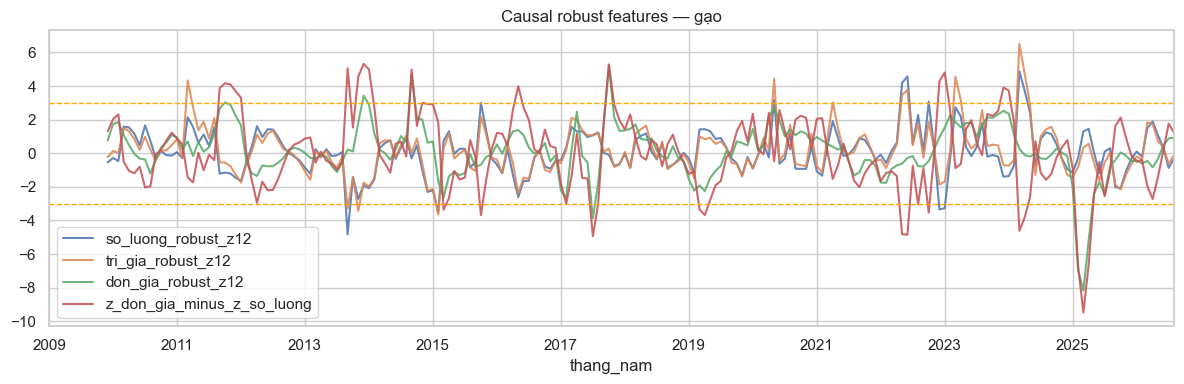

In [5]:
plot_cols = [
    "so_luong_robust_z12",
    "tri_gia_robust_z12",
    "don_gia_robust_z12",
    "z_don_gia_minus_z_so_luong",
]
ax = df[plot_cols].plot(alpha=0.85, title=f"Causal robust features — {SERIES}")
ax.axhline(3, color="orange", ls="--", lw=1)
ax.axhline(-3, color="orange", ls="--", lw=1)
plt.tight_layout()
plt.show()


## 6. Heatmap tương quan (sau warm-up)

Bỏ ~24 tháng đầu để giảm bias từ NaN YoY / rolling.


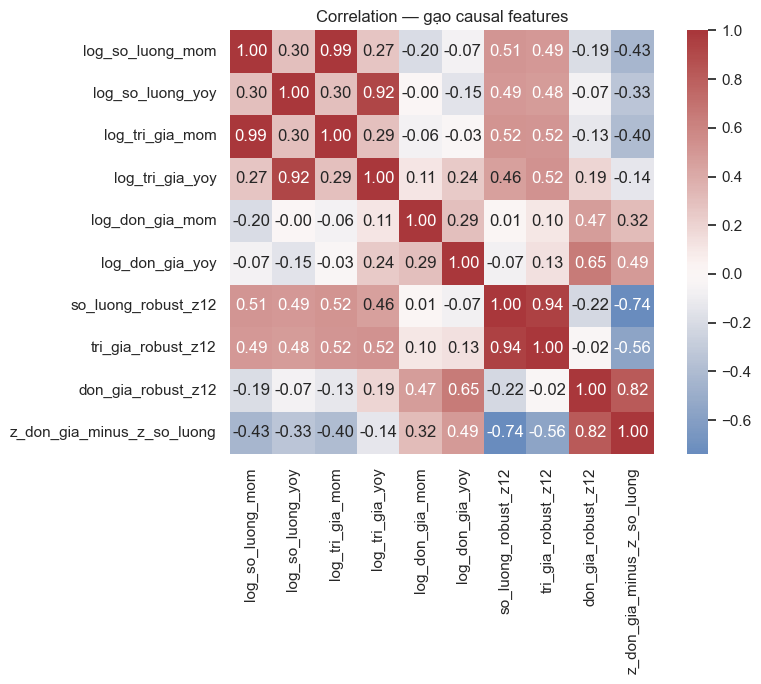

In [6]:
sub = df[FEATURE_COLS].iloc[24:].dropna()
corr = sub.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title(f"Correlation — {SERIES} causal features")
plt.tight_layout()
plt.show()


## 7. So missing giữa 4 chuỗi

Chuỗi ngắn hoặc thiếu đơn giá sẽ có tỷ lệ NaN cao hơn.


,log_so_luong_mom,log_so_luong_yoy,log_tri_gia_mom,log_tri_gia_yoy,log_don_gia_mom,log_don_gia_yoy,so_luong_robust_z12,tri_gia_robust_z12,don_gia_robust_z12,z_don_gia_minus_z_so_luong
gạo,0.005,0.057,0.005,0.057,0.005,0.057,0.052,0.052,0.052,0.052
sắt thép các loại,0.005,0.057,0.005,0.057,0.005,0.057,0.052,0.052,0.052,0.052
xăng dầu các loại,0.005,0.057,0.005,0.057,0.005,0.057,0.052,0.052,0.052,0.052
dầu thô,0.005,0.057,0.005,0.057,0.005,0.057,0.052,0.052,0.052,0.052


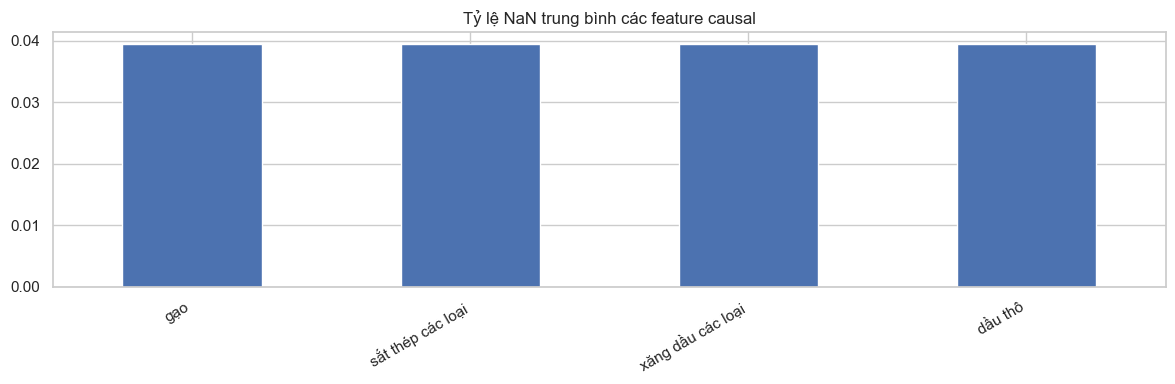

In [7]:
miss = {stem: d[FEATURE_COLS].isna().mean() for stem, d in built.items()}
miss_df = pd.DataFrame(miss).T.round(3)
display(miss_df)
miss_df.mean(axis=1).plot(kind="bar", title="Tỷ lệ NaN trung bình các feature causal")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
